# **Guía de contenido - Semana 4: Introducción a pandas - Segunda parte**
## **Contenidos**

- ### Limpieza y Preparación de Datos

- ### Operaciones de Grupo (GroupBy)

- ### Combinación y Reorganización de Conjuntos de Datos

- ### Miniproyecto 4

> *Versión 2 — actualizada según el Plan Consolidado de Modificaciones del curso. Discretización y variables dummy quedan como lectura optativa; este notebook cierra el curso con la reflexión final sobre uso de IA.*


> **Recordatorio:** en este curso aplica la política de uso responsable de IA presentada en el notebook de la Semana 1. Se resume nuevamente antes del miniproyecto de esta clase.


## **1) Limpieza y Preparación de Datos**

En el ámbito de la ciencia de datos, la **limpieza y preparación de datos** es una fase crítica que consume la mayor parte del tiempo de un analista. Un conjunto de datos "crudo" rara vez es apto para el análisis directo; requiere un tratamiento sistemático para corregir inconsistencias, manejar vacíos y transformar estructuras de modo que la información se vuelva útil y fiable.

A continuación, se presenta una guía detallada sobre los pilares fundamentales de este proceso, acompañada de prácticas diseñadas para consolidar el conocimiento técnico en entornos académicos universitarios.


#### **1.1) Gestión de Valores Faltantes (NA/null)**

En Python, la librería **pandas** utiliza centinelas específicos para identificar la ausencia de información. Para datos numéricos o de punto flotante, se emplea **NaN** (_Not a Number_), mientras que para datos temporales (fechas) se utiliza **NaT** (_Not a Time_). Estos valores no son errores en sí mismos, sino indicadores de que un dato no fue recolectado, se perdió o no es aplicable.

La detección se realiza mediante los métodos **isna()** y **notna()**, que devuelven máscaras booleanas identificando los vacíos. Una vez detectados, existen dos estrategias principales de manejo:

- **Eliminación**: El método **dropna()** permite descartar filas o columnas completas basándose en la presencia de nulos.

- **Imputación**: El método **fillna()** permite reemplazar los vacíos con valores específicos (como el promedio o la mediana) o mediante técnicas de interpolación y propagación de valores (hacia adelante o hacia atrás).



### Ejercicio 1:

Dado un DataFrame llamado `ventas` que contiene columnas de `producto`, `precio` y `fecha_venta`, escriba el código necesario para identificar cuántos valores nulos existen en cada columna y luego elimine únicamente las filas donde el `precio` sea nulo.

**Guía de resolución:** Utilice `ventas.isna().sum()` para el conteo por columnas. Para la eliminación dirigida, use `ventas.dropna(subset=['precio'])`.

In [ ]:
# Tu código aqui:

### Ejercicio 2:

Suponga un conjunto de datos de `estudiantes` con las columnas `nombre` y `calificacion_final`. Muchos estudiantes faltaron al examen, dejando su calificación como `NaN`. Implemente una solución que reemplace todos los valores nulos en la columna `calificacion_final` con la calificación media del grupo, asegurándose de que el cambio se refleje en el DataFrame original.

**Guía de resolución:** Calcule la media primero con `media = estudiantes['calificacion_final'].mean()`. Luego aplique `estudiantes['calificacion_final'].fillna(media, inplace=True)`.

In [ ]:
# Tu código aqui:

### Ejercicio 3:

En un registro meteorológico de temperaturas diarias, existen vacíos ocasionados por fallos temporales en los sensores. Dado que las temperaturas suelen ser similares a las del día anterior, utilice un método de pandas para rellenar los nulos propagando el último valor válido observado hacia adelante, limitando esta acción a un máximo de dos días consecutivos de fallos.

**Guía de resolución:** Utilice el método `fillna` con el parámetro `method='ffill'` y el parámetro `limit=2` para controlar la propagación.

In [ ]:
# Tu código aqui:

#### **1.2) Eliminación de Registros Duplicados**

La redundancia de datos puede sesgar significativamente los resultados estadísticos. Los duplicados ocurren frecuentemente por errores en la consolidación de bases de datos o fallos en los sistemas de registro.

Pandas ofrece **duplicated()**, que identifica si una fila es una repetición de una anterior, y **drop\_duplicates()**, que elimina dichas repeticiones. Es fundamental entender que estos métodos permiten especificar un subconjunto de columnas para definir qué constituye un "duplicado" (por ejemplo, el mismo ID de usuario y la misma fecha), y permiten decidir si se conserva la primera aparición, la última o ninguna.

### Ejercicio 4:

Un sistema de regist# Tu código aqui:ros hospitalarios ha generado múltiples entradas para el mismo paciente en una misma consulta. Dado el DataFrame `consultas` con columnas `id_paciente`, `fecha` y `diagnostico`, identifique si existen filas exactamente iguales y elimínelas conservando solo la primera ocurrencia.

**Guía de resolución:** Aplique `consultas.drop_duplicates(inplace=True)`. Por defecto, este método verifica todas las columnas y mantiene la primera fila encontrada.



In [ ]:
# Tu código aqui:

### Ejercicio 5:

En un DataFrame de `clientes` que incluye `correo_electronico` y `fecha_registro`, se han detectado correos duplicados. Escriba una instrucción que elimine los duplicados basados únicamente en la columna `correo_electronico`, pero asegurándose de conservar el registro con la fecha de registro más reciente (la última observada).

**Guía de resolución:** Ordene primero el DataFrame por fecha y luego use `clientes.drop_duplicates(subset=['correo_electronico'], keep='last')`.




In [ ]:
# Tu código aqui:

### Ejercicio 6:

Cree una función que reciba un DataFrame, identifique qué filas tienen el mismo valor en un conjunto de columnas clave y devuelva un nuevo DataFrame que contenga únicamente las filas que se consideran duplicadas (excluyendo la primera aparición), para que el equipo de auditoría pueda revisarlas.

**Guía de resolución:** Utilice el método `df.duplicated(subset=['col1', 'col2'])` como máscara de filtrado: `duplicados = df[df.duplicated(subset=claves)]`.

In [ ]:
# Tu código aqui:

### Práctica guiada — detectar nulos y duplicados

In [ ]:
# Checkpoint: antes de ejecutar, responda -> cuantas filas duplicadas espera encontrar?
# df.duplicated().sum()


#### **1.3) Transformación de Datos (map y apply)**

La transformación consiste en modificar los valores de una estructura de datos para cumplir con requisitos específicos del análisis.

- **map()**: Se utiliza a nivel de **Serie**. Es ideal para sustituir valores basándose en un diccionario de correspondencias o para aplicar funciones sencillas elemento a elemento.

- **apply()**: Es una herramienta más potente que puede actuar tanto en Series como en **DataFrames**. Permite aplicar funciones complejas (incluyendo funciones lambda) a lo largo de un eje (filas o columnas). Mientras que `map` es eficiente para mapeos directos, `apply` es indispensable para operaciones que requieren lógica condicional o múltiples columnas.

### Ejercicio 7:

Dado un DataFrame con una columna `genero` que contiene los valores "M" y "F", utilice un diccionario de mapeo para transformar estos valores a "Masculino" y "Femenino" respectivamente, utilizando el método adecuado para una Serie.

**Guía de resolución:** Defina un diccionario `mapeo = {'M': 'Masculino', 'F': 'Femenino'}` y aplique `df['genero'] = df['genero'].map(mapeo)`.


In [ ]:
# Tu código aqui:

### Ejercicio 8:

Usted cuenta con un DataFrame de `empleados` con columnas `salario_base` y `bono`. Utilice una función lambda con el método `apply` para crear una nueva columna llamada `ingreso_total` que sea la suma de las dos columnas anteriores para cada fila.

**Guía de resolución:** Utilice `df.apply(lambda row: row['salario_base'] + row['bono'], axis=1)`. Es vital especificar `axis=1` para operar por filas.

In [ ]:
# Tu código aqui:

### Ejercicio 9:

En un conjunto de datos financieros, se requiere normalizar los valores de una columna `monto`. Aplique una transformación que reste el promedio de la columna y divida el resultado por la desviación estándar a cada elemento de dicha columna, utilizando una sola línea de código con `apply`.

**Guía de resolución:**`df['monto'].apply(lambda x: (x - df['monto'].mean()) / df['monto'].std())`.

In [ ]:
# Tu código aqui:

## Actividad con IA: generar casos de prueba

Después de escribir una función (o una operación de limpieza de datos), pida:

"Propón cinco casos de prueba para revisar esta función. Incluye casos normales y casos límite. No modifiques mi código."


**Contexto sugerido para esta clase:** utilice esta actividad luego de escribir su transformación con `map` o `apply` en los Ejercicios 8 y 9, para revisar casos normales y casos límite (valores nulos, vacíos o repetidos) sin modificar su código.


#### **1.4) Renombrar Índices y Columnas**

La legibilidad del código y la claridad de los reportes dependen de nombres de variables intuitivos. El método **rename()** permite cambiar etiquetas de filas (índice) o de columnas sin necesidad de redefinir todo el objeto. Funciona principalmente mediante diccionarios donde la clave es el nombre antiguo y el valor es el nuevo nombre, o mediante funciones que transformen los nombres existentes (por ejemplo, convertir todo a mayúsculas).

### Ejercicio 10:

Dado un DataFrame con columnas tituladas `c1`, `c2` y `c3`, cámbieles el nombre a `ID`, `Nombre` y `Edad` respectivamente, asegurándose de que los cambios se guarden en el objeto original.

**Guía de resolución:** Use `df.rename(columns={'c1': 'ID', 'c2': 'Nombre', 'c3': 'Edad'}, inplace=True)`.



In [ ]:
# Tu código aqui:

### Ejercicio 11:

Implemente una solución que transforme automáticamente todos los nombres de las columnas de un DataFrame de modo que no tengan espacios en blanco iniciales o finales y que todos los caracteres estén en minúsculas.

**Guía de resolución:** Puede pasar la función directamente: `df.rename(columns=lambda x: x.strip().lower())`.



In [ ]:
# Tu código aqui:

### Ejercicio 12:

Suponga que ha transpuesto un DataFrame y ahora sus índices de fila son nombres de países con errores de ortografía. Utilice `rename` con un diccionario para corregir específicamente el índice "Espña" por "España" y "Francia_2" por "Francia".

**Guía de resolución:** Use el parámetro `index` en el método: `df.rename(index={'Espña': 'España', 'Francia_2': 'Francia'}, inplace=True)`.



In [ ]:
# Tu código aqui:

> **📎 Inicio de contenido optativo / lectura autónoma — Discretización (Binning)**
>
> Esta sección profundiza en la discretización de variables numéricas continuas. No es indispensable resolverlo en clase para continuar con el resto del notebook; puede completarse como práctica adicional fuera del horario de encuentro.


### **1.5) Discretización (Binning)**

La discretización es el proceso de convertir variables continuas (como la edad o el ingreso) en variables categóricas o "cubetas".

- **cut()**: Divide los datos en bins de **igual longitud**. Es útil cuando se tienen límites predefinidos (por ejemplo, rangos de edad fijos como 0-18, 19-65, 65+).

- **qcut()**: Divide los datos basándose en **cuantiles de muestra**. Esto garantiza que, aproximadamente, el mismo número de observaciones caiga en cada bin. Es ideal para clasificar datos en niveles como "Bajo", "Medio" y "Alto" manteniendo grupos balanceados.


### Ejercicio 13:

Usted tiene una lista de `edades =`\[1\]. Utilice la función `cut` para segmentar estos datos en tres categorías: "Menor", "Adulto" y "Senior", definiendo manualmente los límites en 0, 18, 65 y 100 años.

**Guía de resolución:** Defina los límites `bins =`\[8\] y las etiquetas `labels = ['Menor', 'Adulto', 'Senior']`. Aplique `pd.cut(edades, bins=bins, labels=labels)`.



In [ ]:
# Tu código aqui:

### Ejercicio 14:

Dado un DataFrame con la columna `puntaje_examen`, utilice `qcut` para dividir a los estudiantes en 4 grupos iguales (cuartiles) basados en su desempeño, de modo que cada grupo represente el 25% de la clase.

**Guía de resolución:**`pd.qcut(df['puntaje_examen'], q=4)`.



In [ ]:
# Tu código aqui:

### Ejercicio 15:

En una base de datos de transacciones bancarias, se desea analizar el comportamiento de los clientes según el monto de sus compras. Cree una nueva columna categórica que divida la columna `monto` en 5 bins de igual frecuencia, y asigne como nombres a esos niveles los números del 1 al 5. Obtenga además el conteo de cuántas transacciones hay en cada nivel.

**Guía de resolución:** Use `df['nivel'] = pd.qcut(df['monto'], q=5, labels=False) + 1` para obtener niveles del 1 al 5. Luego verifique con `df['nivel'].value_counts()`.


In [ ]:
# Tu código aqui:

> **📎 Fin de contenido optativo — Discretización (Binning)**


> **📎 Inicio de contenido optativo / lectura autónoma — Creación de variables dummy**
>
> Esta sección profundiza en la codificación de variables categóricas mediante variables dummy. No es indispensable resolverlo en clase para continuar con el resto del notebook; puede completarse como práctica adicional fuera del horario de encuentro.


### **1.5) Creacion de variables dummies**

En el análisis de datos y el modelado estadístico, muchas variables de interés no son numéricas, sino **categóricas** (como el sexo de una persona, su nivel de estudios o el género de una película). Dado que la mayoría de los algoritmos de modelado matemático y aprendizaje automático requieren entradas numéricas, es necesario transformar estas categorías en una representación que la computadora pueda procesar. Esta transformación se conoce comúnmente como la creación de **variables dummy** o **variables indicadoras**, y en el ámbito del aprendizaje automático también se le llama **one-hot encoding**.

El concepto consiste en convertir una columna que posee k valores distintos en una matriz o DataFrame que tiene k columnas. En cada una de estas nuevas columnas, se asigna un valor de **1** si la observación original pertenecía a esa categoría y un **0** en caso contrario.

Existen casos más complejos donde una sola fila puede pertenecer a múltiples categorías simultáneamente (por ejemplo, una película que es a la vez "Acción" y "Aventura"). En estas situaciones, las categorías suelen estar codificadas en una cadena de texto separada por un delimitador (como una barra vertical `|`). Para procesar estos datos, se utilizan herramientas específicas que expanden cada etiqueta posible en su propia columna indicadora.

Además, al integrar estas nuevas columnas en un conjunto de datos principal, es una práctica recomendada añadir un **prefijo** al nombre de las columnas generadas. Esto facilita la identificación de la variable original de la cual provienen las categorías y mantiene el orden dentro del DataFrame resultante.



### Ejemplos Contextualizados

**Ejemplo Teórico (basado en el procesamiento de claves):** Supongamos un conjunto de datos simple con una columna llamada "Clave" que contiene los valores `['b', 'b', 'a', 'c', 'a', 'b']`. Al aplicar la función de creación de dummies, el sistema identifica tres categorías únicas: 'a', 'b' y 'c'. El resultado será un nuevo DataFrame con tres columnas etiquetadas como 'a', 'b' y 'c'. En la primera fila (que originalmente era 'b'), la columna 'b' tendrá un 1, mientras que 'a' y 'c' tendrán 0.

**Ejemplo Práctico (aplicado al análisis demográfico):** En una encuesta de salud, los encuestadores registran el sexo de los participantes como "Masculino" o "Femenino". Para realizar una regresión lineal que evalúe el impacto del sexo en el peso, el analista transforma esta variable categórica. Se generan dos columnas: `sexo_femenino` y `sexo_masculino`. Si un participante es hombre, su fila mostrará un 1 en la columna masculina y un 0 en la femenina, permitiendo que el modelo estadístico realice cálculos numéricos sobre esta información.



### Ejercicio 16

Dado un objeto de tipo Series llamado `estudios` que contiene los valores: `['Grado', 'Posgrado', 'Grado', 'Doctorado', 'Posgrado']`. Se solicita generar la matriz de variables indicadoras correspondiente.

**Guía de resolución:**  utilizarse la función `pd.get_dummies(estudios)`. El resultado será un DataFrame con 5 filas y 3 columnas correspondientes a las categorías únicas presentes en la serie. Verifique que cada fila contenga un solo 1 indicando la categoría correcta.



In [ ]:
# Tu código aqui:

### Ejercicio 17

Dado un DataFrame llamado `datos_ventas` que tiene las columnas `ID_Venta` (numérico) y `Canal` (categórico con valores: 'Online', 'Tienda', 'Telefónico'). Se requiere crear las variables dummy para la columna `Canal`, pero asegurándose de que las nuevas columnas tengan el prefijo "Venta" y que se unan al DataFrame original descartando la columna categórica inicial.

**Guía de resolución:** Primero, genere las dummies usando `pd.get_dummies(datos_ventas['Canal'], prefix='Venta')`. Luego, utilice el método `.join()` para combinar este resultado con `datos_ventas[['ID_Venta']]` (seleccionando solo la columna numérica). Finalmente, verifique que la columna original 'Canal' ya no esté presente y que existan columnas como `Venta_Online`.

In [ ]:
# Tu código aqui:


### Ejercicio 18

Dado un conjunto de datos de habilidades de programadores donde una columna llamada `Lenguajes` contiene etiquetas múltiples en formato de cadena, por ejemplo: `"Python|SQL"`, `"R|Python"`, `"SQL"`. Se solicita crear una matriz indicadora que separe cada lenguaje en su propia columna, identificando la presencia de cada uno de forma individual.

**Guía de resolución:** Para este caso de membresía múltiple, no se usa la función general, sino el método de acceso a cadenas de la serie: `df['Lenguajes'].str.get_dummies('|')`. El sistema detectará las tres etiquetas únicas (Python, R, SQL) y creará columnas para cada una. Una fila que originalmente contenía `"Python|SQL"` tendrá un 1 tanto en la columna `Python` como en la columna `SQL`.

In [ ]:
# Tu código aqui:

> **📎 Fin de contenido optativo — Creación de variables dummy**


## **2) Operaciones de Grupo (GroupBy)**

Las operaciones de grupo representan una de las tareas más críticas en el flujo de trabajo de análisis de datos. Este proceso permite categorizar un conjunto de datos y aplicar funciones específicas a cada grupo para extraer información significativa. El marco conceptual para entender estas operaciones se denomina **split-apply-combine** (dividir-aplicar-combinar).

Este paradigma se divide en tres etapas lógicas:

-   **Dividir (Split):** Los datos contenidos en un objeto de pandas (como un DataFrame o una Serie) se reparten en trozos o grupos basados en una o más claves proporcionadas. Estas claves pueden ser nombres de columnas, arreglos de valores, diccionarios o incluso funciones.
-   **Aplicar (Apply):** Se aplica una función a cada grupo de forma independiente. Esta operación suele ser una agregación (como calcular la media o la suma), una transformación o una filtración.
-   **Combinar (Combine):** Los resultados de las aplicaciones individuales se reúnen en un nuevo objeto resultante, cuya forma dependerá de la operación realizada.

Cuando se invoca el método `groupby` en pandas, se crea un objeto especial llamado **GroupBy**. Es importante destacar que este objeto, por sí mismo, no realiza ningún cálculo inmediato; simplemente contiene la información necesaria sobre las claves de grupo para ejecutar operaciones posteriores.

**Claves de agrupación y comportamiento** La agrupación puede realizarse mediante diversos mecanismos:

-   **Nombres de columnas:** Es la forma más común, donde los valores únicos de una columna definen los grupos.
-   **Múltiples claves:** Si se pasa una lista de nombres de columnas, el resultado tendrá un índice jerárquico compuesto por los pares únicos de claves observadas.
-   **Funciones:** Cualquier función pasada como clave se invocará una vez por cada valor del índice, utilizando los valores devueltos como nombres de grupo.

Un aspecto relevante en las operaciones de agregación numérica (como `.mean()`) es el tratamiento de las llamadas **columnas molestas** (nuisance columns). Si un DataFrame contiene columnas que no son de tipo numérico, pandas las excluirá automáticamente del cálculo de la agregación para evitar errores de tipo. Asimismo, por defecto, los valores faltantes (NA) en las claves de grupo se excluyen del resultado.

**Flexibilidad en la agregación** Pandas ofrece métodos optimizados para las estadísticas más comunes, pero también permite una personalización profunda a través de:

-   **El método** **agg** **(o** **aggregate****):** Permite aplicar múltiples funciones a la vez o asignar funciones específicas a diferentes columnas mediante el uso de diccionarios.-   **El método** **apply****:** Es la herramienta más general, permitiendo dividir el objeto en trozos, invocar una función personalizada en cada uno y luego intentar concatenar los resultados.



### Ejercicio 19

Dado un DataFrame llamado `datos_ventas` que contiene las columnas `Tienda`, `Departamento` y `Ventas_Semanales`, se solicita obtener el promedio de ventas por cada tipo de tienda.

**Guía de resolución:** Para resolver este problema, debe utilizar el método `groupby` seleccionando la columna `Tienda` como clave de agrupación. Posteriormente, debe aplicar el método de agregación `.mean()` sobre la columna de interés. La sintaxis lógica consiste en acceder al DataFrame, agrupar por la variable categórica y calcular la estadística descriptiva para la variable numérica. El resultado será una Serie indexada por los identificadores de cada tienda.



In [ ]:
# Tu código aqui:

### Ejercicio 20

Dado un conjunto de datos sobre propinas en un restaurante con las columnas `dia`, `fumador`, `total_factura` y `porcentaje_propina`, realice una operación que devuelva simultáneamente el valor máximo, el mínimo y el promedio del porcentaje de propina, agrupando los datos por el día de la semana y la condición de fumador.

**Guía de resolución:** Este ejercicio requiere una agrupación por múltiples claves y la aplicación de varias funciones de agregación. Primero, aplique `groupby` pasando una lista con las columnas `["dia", "smoker"]`. Segundo, acceda específicamente a la columna `porcentaje_propina` del objeto GroupBy resultante. Tercero, utilice el método `.agg()` pasando una lista de cadenas con los nombres de las funciones deseadas: `["max", "min", "mean"]`. El objeto resultante será un DataFrame con un índice jerárquico (por día y fumador) y columnas para cada estadística calculada.

In [ ]:
# Tu código aqui:

### Ejercicio 21

Dado un DataFrame de empleados con las columnas `Nombre`, `Ciudad` y `Salario`, escriba una función que identifique al empleado con el salario más alto de cada ciudad y aplíquela al conjunto de datos utilizando las herramientas de operaciones de grupo.

**Guía de resolución:** Este reto requiere el uso de la función `apply` para realizar una operación personalizada por grupo.

-   Defina una función de ayuda (por ejemplo, `obtener_maximo`) que reciba un grupo y devuelva la fila correspondiente al salario máximo utilizando el método `.loc` junto con `.idxmax()` sobre la columna `Salario`.
-   Agrupe el DataFrame original por la columna `Ciudad`.
-   Invoque el método `.apply()` pasando la función definida anteriormente. Pandas se encargará de dividir los datos por ciudad, extraer el registro del salario máximo en cada una y combinar los resultados en un nuevo DataFrame informativo.

In [ ]:
# Tu código aqui:

### Práctica guiada — crear `total_venta` y agrupar

In [ ]:
# Checkpoint: cree la columna 'total_venta' (precio * cantidad) y luego agrupe por categoria
# sumando 'total_venta'. Antes de ejecutar, escriba cuantas filas cree que va a tener el resultado
# agrupado (deberia ser igual a la cantidad de categorias distintas).
# df_ventas['total_venta'] = df_ventas['precio'] * df_ventas['cantidad']
# df_ventas.groupby('categoria')['total_venta'].sum()


## **3) Combinación y Reorganización de Conjuntos de Datos**

La integración de datos provenientes de múltiples fuentes es una tarea fundamental en el análisis de datos. En entornos de programación orientados a objetos como el ecosistema de Python, existen tres herramientas principales para realizar esta tarea: `merge`, `join` y `concat`. Aunque comparten el objetivo de combinar información, difieren significativamente en su lógica operativa y en cómo gestionan los índices y las claves. Se presentan diferentes casos de uso comun:

**a) merge** **(Combinación basada en claves)** La función `pd.merge` implementa operaciones de unión similares a las de las bases de datos relacionales (SQL). Su lógica se centra en conectar filas utilizando una o más "claves" o columnas comunes. Es la herramienta de elección para realizar operaciones complejas como uniones "muchos a uno" o "muchos a muchos".

-   **Lógica de unión:** Por defecto, realiza una unión de tipo *inner* (intersección), conservando solo las claves que aparecen en ambos conjuntos. Sin embargo, permite otros tipos: *left* (preserva todas las claves del conjunto izquierdo), *right* (todas las del derecho) y *outer* (la unión de todas las claves, introduciendo valores nulos donde no hay coincidencia).-   **Flexibilidad:** Permite especificar columnas con nombres diferentes en cada conjunto mediante los argumentos `left_on` y `right_on`.

**b) join** **(Combinación basada en índices)** El método `.join` es una forma simplificada de combinar datos, diseñada específicamente para unir conjuntos basándose en sus índices (etiquetas de fila) en lugar de columnas arbitrarias.

-   **Diferencia operativa:** A diferencia de `merge`, el método `.join` realiza por defecto una unión de tipo *left* (preserva el índice del objeto original). Es ideal cuando se desea integrar datos de múltiples objetos que comparten el mismo índice pero tienen columnas diferentes.-   **Uso avanzado:** También permite unir el índice de un conjunto con una columna específica de otro mediante el argumento `on`.

**c) concat** **(Concatenación o apilamiento)** La función `pd.concat` se utiliza para "pegar" u objetos a lo largo de un eje determinado (filas o columnas). A diferencia de las anteriores, no busca necesariamente una relación lógica basada en el contenido de las celdas, sino que apila las estructuras.

-   **Ejes de operación:** Si se aplica sobre el eje de las filas (`axis=0`), el resultado es un objeto más largo. Si se aplica sobre el eje de las columnas (`axis=1`), el resultado es un objeto más ancho.-   **Jerarquías:** Permite crear índices jerárquicos (*MultiIndex*) mediante el argumento `keys`, lo que ayuda a identificar la fuente original de los datos una vez combinados.

En resumen, mientras que `merge` y `join` se basan en la alineación de valores (claves o índices), `concat` se basa en la disposición estructural de los conjuntos.
Veremos a continuación algunos ejemplos de aplicación de las diferentes formas de concatenar tablas:


In [ ]:
# Ejemplo 1) Uso de merge tipo INNER

import pandas as pd

# DataFrame de clientes
clientes = pd.DataFrame({
    'cliente_id': [1, 2, 3, 4],
    'nombre': ['Ana', 'Luis', 'Carlos', 'María']
})
print(clientes)
# DataFrame de ventas
ventas = pd.DataFrame({
    'cliente_id': [1, 2, 2, 4],
    'monto': [100, 200, 150, None]
})
print(ventas)

# Merge tipo INNER
df_merge = pd.merge(clientes, ventas, on='cliente_id', how='inner')  # Columna común: 'cliente_id'. Considera SOLAMENTE los clientes que tienen ventas.
print(df_merge)

   cliente_id  nombre
0           1     Ana
1           2    Luis
2           3  Carlos
3           4   María
   cliente_id  monto
0           1  100.0
1           2  200.0
2           2  150.0
3           4    NaN
   cliente_id nombre  monto
0           1    Ana  100.0
1           2   Luis  200.0
2           2   Luis  150.0
3           4  María    NaN


In [8]:
# Ejemplo 2) Uso de merge tipo LEFT

df_merge = pd.merge(clientes, ventas, on='cliente_id', how='left')
print(df_merge)

   cliente_id  nombre  monto
0           1     Ana  100.0
1           2    Luis  200.0
2           2    Luis  150.0
3           3  Carlos    NaN
4           4   María    NaN


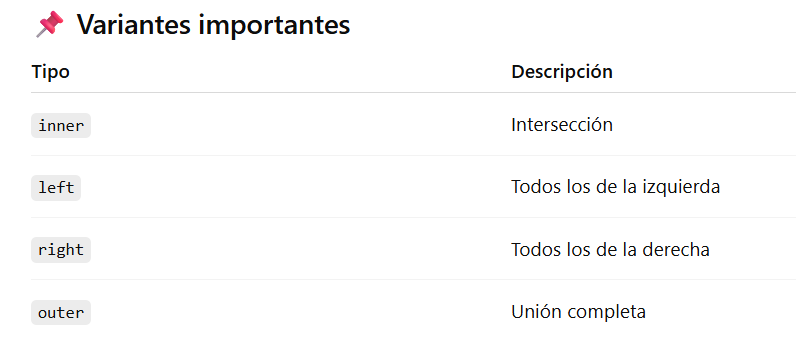

In [ ]:
# Ejemplo 3) Uso de CONCAT (por filas)

df1 = pd.DataFrame({'A': [1, 2]})
print(df1)
df2 = pd.DataFrame({'A': [3, 4]})
print(df2)
print("")
df_concat = pd.concat([df1, df2], axis=0) # axis=0 apilamos por filas
print(df_concat)

   A
0  1
1  2
   A
0  3
1  4

   A
0  1
1  2
0  3
1  4


In [ ]:
# Ejemplo 4) Uso de CONCAT (por columnas)
df_concat = pd.concat([df1, df2], axis=1)  # axis=1 apilamos por columnas
print(df_concat)

   A  A
0  1  3
1  2  4


In [12]:
# Ejemplo 3) Uso de Join (por indices)

df1 = pd.DataFrame({'A': [1, 2]}, index=['a', 'b'])
df2 = pd.DataFrame({'B': [3, 4]}, index=['a', 'b'])

df_join = df1.join(df2)
print(df_join)

   A  B
a  1  3
b  2  4


## Actividad con IA: comparar soluciones

Compare dos soluciones simples al mismo problema. Solicite:

"Compara estas dos soluciones para un estudiante principiante. Indica cuál es más clara, cuál es más fácil de mantener y si ambas usan conceptos vistos en clase."


**Contexto sugerido para esta clase:** compare dos formas distintas de combinar los mismos DataFrames (por ejemplo, `merge` vs. `concat` cuando ambas sean aplicables) y evalúe cuál es más clara para un principiante.


### Ejercicio 22

Dado el siguiente escenario: Se cuenta con un DataFrame llamado `clientes` que contiene las columnas `ID_Cliente` y `Nombre`, y otro DataFrame llamado `pedidos` con las columnas `ID_Pedido`, `ID_Cliente` y `Monto`. Se desea obtener un listado de todos los pedidos realizados, incluyendo el nombre del cliente correspondiente, pero asegurándose de no perder ningún registro de la tabla `pedidos` incluso si el ID del cliente no se encuentra en la tabla de `clientes`.

**Guía de resolución:** Para resolver este problema, se debe utilizar `pd.merge`. Dado que el objetivo es mantener todos los registros del conjunto que contiene los pedidos, se debe realizar una unión de tipo *left* (si `pedidos` es el primer argumento) o *right* (si es el segundo). La clave de unión será la columna común `ID_Cliente`. La sintaxis recomendada sería `pd.merge(pedidos, clientes, on="ID_Cliente", how="left")`.



In [ ]:
# Tu código aqui:



### Ejercicio 23


Dado el siguiente escenario: Un analista tiene dos Series independientes, `s1` y `s2`. Ambas tienen índices de texto que no se solapan. El analista necesita combinar ambas estructuras en un solo objeto de tipo DataFrame, de modo que cada Serie original ocupe una columna distinta, alineando sus índices de forma que se cree la unión total de las etiquetas.

**Guía de resolución:** En este caso, la herramienta adecuada es `pd.concat` utilizando el argumento `axis=1` (o `axis="columns"`). Al tratarse de Series sin solapamiento de índices, el resultado será un DataFrame donde las filas correspondientes a etiquetas ausentes en una de las Series se llenarán con valores nulos (NaN). Además, se pueden asignar nombres a las columnas resultantes pasando una lista al argumento `keys`.



In [ ]:
# Tu código aqui:



### Ejercicio 24

Dado el siguiente escenario: Se tiene un DataFrame `datos_principales` indexado por nombres de ciudades y un DataFrame `clima_promedio` también indexado por ciudades. Se requiere integrar la columna `Temperatura` de `clima_promedio` dentro de `datos_principales` de la manera más eficiente posible, asumiendo que ambos objetos ya están alineados por sus etiquetas de fila. ¿Qué método es el más directo y cuál es su comportamiento respecto a las ciudades que podrían estar en `datos_principales` pero no en `clima_promedio`?

**Guía de resolución:** El método más directo es utilizar `.join`. Al invocar `datos_principales.join(clima_promedio)`, el sistema buscará por defecto las coincidencias en los índices de ambos objetos. El comportamiento estándar de `.join` es realizar un *left join*, lo que significa que el resultado final conservará exactamente todas las ciudades (filas) que existían en `datos_principales`. Si una ciudad de `datos_principales` no existe en `clima_promedio`, la columna `Temperatura` mostrará un valor nulo para esa fila.

In [ ]:
# Tu código aqui:

## Uso responsable de IA (resumen)

La IA puede utilizarse como apoyo para aprender, pero no para reemplazar el razonamiento propio. Antes de consultar IA, escriba un intento personal o una explicación de lo que no entiende.

Se permite pedir pistas, explicaciones de errores, revisión de código propio y casos de prueba. No se permite copiar soluciones completas sin comprenderlas. Toda entrega debe incluir una breve declaración de uso de IA.

*(Política completa disponible en el notebook de la Semana 1.)*


> **Nota:** este miniproyecto se organiza en etapas (crear datos, exploración, filtrado, limpieza, resúmenes). Complete cada etapa antes de avanzar. La IA solo puede usarse para explicar filtros, groupby y generar casos de prueba de limpieza; no para producir el análisis completo ni gráficos no vistos en clase.


## **4) Miniproyecto 4 — Análisis Básico de Ventas con pandas**

## Objetivo

Desarrollar un pequeño proyecto de análisis de datos utilizando `pandas` para:

- cargar datos,
- explorar información,
- filtrar registros,
- limpiar datos simples,
- y generar algunos resúmenes básicos.

El objetivo es practicar las operaciones fundamentales de manipulación de datos tabulares vistas durante la Semana 4.

---

# Contexto del problema

Una tienda desea realizar un análisis inicial de sus ventas utilizando Python y pandas.

La empresa dispone de un conjunto de datos con información de productos vendidos.

Tu tarea será cargar el conjunto de datos, explorarlo y responder algunas preguntas básicas sobre las ventas.

---

# Parte 1 — Crear el conjunto de datos

Crear un DataFrame llamado:

```python
df_ventas
```

El DataFrame debe contener al menos 10 registros y las siguientes columnas:

| columna | descripción |
|---|---|
| producto | nombre del producto |
| categoria | categoría del producto |
| precio | precio unitario |
| cantidad | cantidad vendida |
| vendedor | nombre del vendedor |
| ciudad | ciudad de venta |

---

# Parte 2 — Exploración inicial

Realizar las siguientes tareas:

## Mostrar información general

Utilizar métodos para:

- visualizar las primeras filas,
- conocer las dimensiones del DataFrame,
- observar los tipos de datos,
- listar las columnas disponibles.

---

## Obtener estadísticas básicas

Calcular:

- promedio de precios,
- cantidad total de productos vendidos,
- precio máximo,
- precio mínimo.

---

# Parte 3 — Filtrado de información

Realizar filtros para:

## Productos caros

Mostrar los productos cuyo precio sea mayor a 500.

---

## Ventas por ciudad

Mostrar únicamente las ventas realizadas en una ciudad específica.

---

## Ventas por categoría

Mostrar únicamente productos de una categoría determinada.

---

# Parte 4 — Limpieza simple de datos

Agregar intencionalmente:

- al menos un valor faltante,
- y un registro duplicado.

Luego:

- identificar valores faltantes,
- eliminar duplicados,
- verificar nuevamente el DataFrame.

---

# Parte 5 — Agrupamiento básico

Utilizar `groupby()` para:

- calcular ventas totales por categoría,
- calcular cantidad total vendida por vendedor.

---

# Parte 6 — Transformación simple

Crear una nueva columna llamada:

```python
total_venta
```

La columna debe calcular:

```python
precio * cantidad
```

---

# Requisitos técnicos

El proyecto debe incluir:

- creación de DataFrames,
- uso de Series,
- selección de columnas,
- filtrado con condiciones,
- uso de `.loc` o `.iloc`,
- identificación de valores faltantes,
- eliminación de duplicados,
- agrupamiento con `groupby()`,
- creación de nuevas columnas.

---

# Recomendaciones

- Utilizar nombres claros para variables.
- Mantener el notebook ordenado.
- Separar cada parte utilizando títulos Markdown.
- Mostrar resultados intermedios para verificar el análisis.

---

# Ejemplo esperado de salida

```text
Promedio de precios: 720.5

Productos con precio mayor a 500:
Notebook
Monitor
Impresora

Ventas totales por categoría:
Electrónica    152000
Oficina         83000
```

---

# Desafío opcional

Agregar alguna de las siguientes mejoras:

- ordenar productos por precio,
- exportar el DataFrame a Excel,
- crear filtros combinados,
- calcular el producto más vendido,
- generar un resumen final automático.

---

# Criterios de evaluación

Se tendrá en cuenta:

- correcta utilización de pandas,
- organización del notebook,
- claridad del análisis,
- uso adecuado de filtros y agrupamientos,
- correcta manipulación de datos tabulares.


## Declaración de uso de IA

- ¿Utilicé IA en esta actividad?: Sí / No
- Herramienta utilizada:
- ¿Para qué la utilicé?:
- Intento propio antes de usar IA:
- Prompt utilizado:
- Sugerencias aceptadas:
- Sugerencias descartadas:
- ¿Qué aprendí al revisar la respuesta?:


## Reflexión final

Responda brevemente:

1. ¿Qué parte resolví sin IA?
2. ¿En qué momento consulté IA?
3. ¿Qué sugerencia me resultó útil?
4. ¿Qué sugerencia descarté o modifiqué?
5. ¿Puedo explicar todo el código entregado?


## Cierre del curso

Este miniproyecto integra lo trabajado en las 10 clases: variables y tipos, estructuras de datos, funciones, control de flujo y pandas. Antes de entregar, revise el checklist final de control del Plan Consolidado (carga realista, práctica guiada, uso de IA como tutor, declaración de IA, consignas claras y reflexión final).
